In [1]:
import import_ipynb
import data_analysis_classification

c:\Users\Natti\anaconda3\envs\ml_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ขนาดชุดข้อมูล: Train (8101, 27), Test (2026, 27)
ฟีเจอร์ที่ผ่านเกณฑ์โหวต (>=3): ['Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Total_Revolving_Bal', 'Contacts_Count_12_mon', 'Total_Trans_Amt', 'Months_Inactive_12_mon', 'Total_Relationship_Count']


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, mean_absolute_percentage_error
from sklearn.datasets import load_diabetes
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import AdaBoostClassifier, AdaBoostRegressor
from mlxtend.plotting import plot_decision_regions

In [3]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

# Plain NumPy arrays, 1D labels (avoids Series/2D shape problems everywhere below)
X_train = np.asarray(data_analysis_classification.X_scaled, dtype=float)
X_test  = np.asarray(data_analysis_classification.X_test_scaled, dtype=float)
y_train = np.asarray(data_analysis_classification.y_train).ravel().astype(int)
y_test  = np.asarray(data_analysis_classification.y_test).ravel().astype(int)

print(X_train.shape, X_test.shape, "positive rate (train/test):", y_train.mean().round(3), y_test.mean().round(3))

(8101, 27) (2026, 27) positive rate (train/test): 0.161 0.16


In [4]:
class AdaBoost:
    def __init__(self, regression=False, n_estimators=50, learning_rate=1.0, random_state=0):
        self.regression = regression
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.random_state = random_state
        self.stumps = []
        self.weights = []

    def _update_weights(self, args):
        if self.regression:
            weights, beta, loss_function = args
            weights *= beta ** (1 - loss_function)
        else:
            weights, wrong_predictions, stump_weight = args
            weights[wrong_predictions] *= np.exp(stump_weight)

        return weights

    @staticmethod
    def _normalize(weights: np.ndarray):
        return weights / sum(weights)

    def fit(self, X, y):
        n_samples = len(y)
        self.K = len(np.unique(y))
        weights = np.ones(n_samples) / n_samples

        for _ in range(self.n_estimators):
            if self.regression:
                stump = DecisionTreeRegressor(max_depth=3, random_state=self.random_state)
                stump_predictions = stump.fit(X, y, sample_weight=weights).predict(X)

                abs_instance_errors = abs(stump_predictions - y)
                adjusted_instance_errors = abs_instance_errors / max(abs_instance_errors)
                adjusted_stump_error = sum(weights * adjusted_instance_errors)

                if adjusted_stump_error >= 0.5:
                    self.stumps.pop(-1)
                    break

                beta = adjusted_stump_error / (1 - adjusted_stump_error)
                stump_weight = self.learning_rate * np.log(1 / beta)
                args = [weights, beta, adjusted_instance_errors]
            else:
                stump = DecisionTreeClassifier(max_depth=1, random_state=self.random_state)
                stump_predictions = stump.fit(X, y, sample_weight=weights).predict(X)

                wrong_predictions = stump_predictions != y
                r = sum(weights[wrong_predictions])   # weighted_error_rate
                stump_weight = self.learning_rate * np.log((1 - r) / r) + np.log(self.K - 1)
                args = [weights, wrong_predictions, stump_weight]

            self.stumps.append(stump)
            self.weights.append(stump_weight)
            weights= self._update_weights(args)
            weights = self._normalize(weights)

    def _max_weighted_votes(self, samples):
        n_samples = len(samples)
        sample_indexes = np.array(range(n_samples))
        prediction_weights = np.zeros((n_samples, self.K))

        for i in range(self.n_estimators):
            stump_prediction = self.stumps[i].predict(samples)
            prediction_weights[sample_indexes, stump_prediction] += self.weights[i]

        return np.argmax(prediction_weights, axis=1)

    def _weighted_median_prediction(self, samples):
        n_samples = len(samples)
        sample_indexes = np.arange(n_samples)
        predictions = np.array([stump.predict(samples) for stump in self.stumps]).T
        sorted_pred_indexes = np.argsort(predictions, axis=1)

        # Find index of median prediction for each sample
        cumsum_weights = np.array(self.weights)[sorted_pred_indexes].cumsum(axis=1)
        is_over_median = cumsum_weights >= 0.5 * sum(self.weights)   # True/False matrix
        median_indexes = is_over_median.argmax(axis=1)
        median_prediction_indexes = sorted_pred_indexes[sample_indexes, median_indexes]

        return predictions[sample_indexes, median_prediction_indexes]

    def predict_proba(self, samples):
        n_samples = len(samples)
        scores = np.zeros((n_samples, self.K))

        for stump, weight in zip(self.stumps, self.weights):
            predictions = stump.predict(samples)

            for i, prediction in enumerate(predictions):
                scores[i, int(prediction)] += weight

        # Normalize scores to obtain probability-like values
        scores = scores / scores.sum(axis=1, keepdims=True)

        return scores

    def predict(self, samples):
        if self.regression:
            return self._weighted_median_prediction(samples)
        else:
            return self._max_weighted_votes(samples)

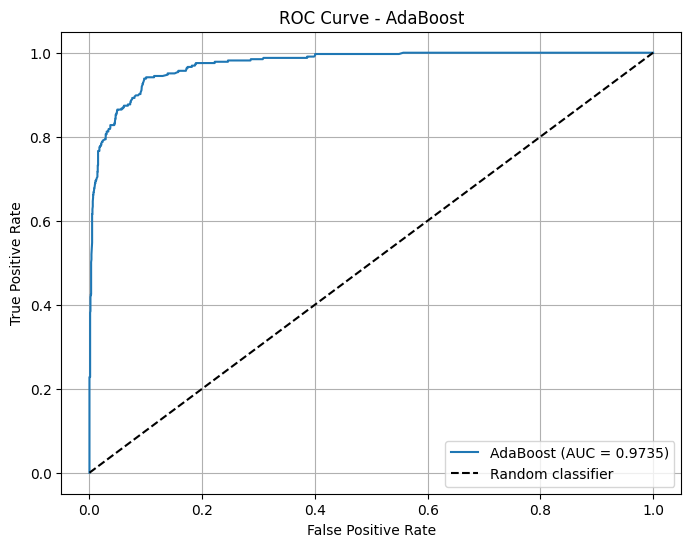

Bank Churn Accuracy: 0.9442250740375123
Precision: 0.9045801526717557
Recall: 0.7292307692307692
F1 Score: 0.807495741056218
ROC-AUC: 0.9735431646542757


In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Train your model
clf = AdaBoost(
    regression=False,
    n_estimators=50,
    learning_rate=1.0,
    random_state=0
)

clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
# Get positive-class scores
y_score = clf.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_score)
auc_score = roc_auc_score(y_test, y_score)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"AdaBoost (AUC = {auc_score:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - AdaBoost")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print("Bank Churn Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, clf.predict_proba(X_test)[:, 1]))